# Stream C — `stream_c_results.ipynb`

**Purpose:** Consolidate all Stream C outputs into a full evaluation:
- Feature-wise AUROC breakdown (21 features)
- Compare Stream C vs Stream A vs Stream B vs baselines
- Produce paper-ready figures and CSV tables
- Confirm final `stream_c_*.pkl` files are ready for `05_fusion/`

**Known results going in:**
- Stream C LR probe: NC test=0.6072, VERITE=0.5000, MMFake=0.5071
- Stream A: NC test=0.7320, VERITE=0.5530, MMFake=0.5810
- Stream B (best): NC test=0.7956, VERITE=0.7188, MMFake=0.9844

**Fixed:** Stream B comparison values are read from `paper/tables/stream_b_results.csv` when available instead of using stale hardcoded leaked numbers.

## 0. Environment Check

In [ ]:
import os
from pathlib import Path

os.chdir(r"E:\eve-rag")
ROOT = Path(r"E:\eve-rag")

print("Forced working directory:", Path.cwd())
print("Forced ROOT:", ROOT)
assert (ROOT / "src" / "utils" / "paths.py").exists()

In [1]:
import torch
print(f"PyTorch: {torch.__version__}")
print(f"CUDA: {torch.cuda.is_available()}")

PyTorch: 2.6.0+cu124
CUDA: True


## 1. Imports & Paths

In [2]:
import os, sys, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

from sklearn.metrics import (
    roc_auc_score, accuracy_score, roc_curve,
    confusion_matrix, classification_report
)
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# ── Project root ──────────────────────────────────────────────────────────────
try:
    ROOT = Path(__file__).resolve().parents[2]
except NameError:
    ROOT = Path(os.getcwd())
    while not (ROOT / 'src' / 'utils' / 'paths.py').exists():
        ROOT = ROOT.parent
        if ROOT == ROOT.parent:
            ROOT = Path(os.getcwd()); break

sys.path.insert(0, str(ROOT))
print(f"Project root: {ROOT}")

STANCE_DIR = ROOT / 'cache' / 'stance_scores'
FIG_DIR    = ROOT / 'paper' / 'figures'
TAB_DIR    = ROOT / 'paper' / 'tables'

# Verify files
for name in ('stream_c_train.pkl', 'stream_c_val.pkl', 'stream_c_test.pkl',
             'stream_c_verite.pkl', 'stream_c_mmfake.pkl', 'stream_c_feat_names.pkl'):
    p = STANCE_DIR / name
    print(f"  {'✅' if p.exists() else '❌ MISSING'} {name}")

Project root: f:\GitHub\eve-rag
  ✅ stream_c_train.pkl
  ✅ stream_c_val.pkl
  ✅ stream_c_test.pkl
  ✅ stream_c_verite.pkl
  ✅ stream_c_mmfake.pkl
  ✅ stream_c_feat_names.pkl


## 2. Load Stream C Features

In [3]:
def load_pkl(path):
    with open(path, 'rb') as f:
        return pickle.load(f)

feat_names_raw = load_pkl(STANCE_DIR / 'stream_c_feat_names.pkl')
# Unwrap: pkl stores {'feat_names': [list]} not a plain list
if isinstance(feat_names_raw, dict):
    feat_names = feat_names_raw.get('feat_names', list(feat_names_raw.values())[0])
else:
    feat_names = list(feat_names_raw)
print(f"Feature names ({len(feat_names)}): {feat_names}")

sc = {
    'train':  load_pkl(STANCE_DIR / 'stream_c_train.pkl'),
    'val':    load_pkl(STANCE_DIR / 'stream_c_val.pkl'),
    'test':   load_pkl(STANCE_DIR / 'stream_c_test.pkl'),
    'verite': load_pkl(STANCE_DIR / 'stream_c_verite.pkl'),
    'mmfake': load_pkl(STANCE_DIR / 'stream_c_mmfake.pkl'),
}

print()
for split, data in sc.items():
    X = data['features']
    y = data['labels']
    nan_count = np.isnan(X).sum()
    pos = y.sum()
    print(f"  {split:8s}: {X.shape}  NaN={nan_count} {'✅' if nan_count==0 else '❌'}  "
          f"pos={pos} ({100*pos/len(y):.1f}%)")

Feature names (21): ['img_sim_max', 'img_sim_mean', 'img_sim_std', 'img_sim_top1', 'txt_sim_max', 'txt_sim_mean', 'txt_sim_top1', 'cross_sim_max', 'cross_sim_mean', 'stance_score', 'ce_max_ent', 'ce_mean_ent', 'ce_max_con', 'ce_mean_con', 'ce_net_stance', 'ce_entropy', 'ce_top1_ent', 'ce_top1_con', 'bi_max_sim', 'bi_mean_sim', 'bi_std_sim']

  train   : (71072, 21)  NaN=0 ✅  pos=35536 (50.0%)
  val     : (7024, 21)  NaN=0 ✅  pos=3512 (50.0%)
  test    : (7264, 21)  NaN=0 ✅  pos=3632 (50.0%)
  verite  : (1001, 21)  NaN=0 ✅  pos=663 (66.2%)
  mmfake  : (10000, 21)  NaN=0 ✅  pos=7000 (70.0%)


## 3. Train LR Probe & Get Predictions

In [4]:
# Train on NC train, evaluate on all splits
scaler = StandardScaler()
X_tr = scaler.fit_transform(sc['train']['features'])
y_tr = sc['train']['labels']

lr = LogisticRegression(max_iter=1000, C=1.0, random_state=42)
lr.fit(X_tr, y_tr)
print("LR probe trained.")

# Get probs for all splits
preds = {}
for split, data in sc.items():
    X = scaler.transform(data['features'])
    probs = lr.predict_proba(X)[:, 1]
    labels = data['labels']
    auc = roc_auc_score(labels, probs)
    acc = accuracy_score(labels, (probs >= 0.5).astype(int))
    preds[split] = {'probs': probs, 'labels': labels, 'auroc': auc, 'acc': acc}
    print(f"  {split:8s}: AUROC={auc:.4f}  Acc={acc:.4f}")

LR probe trained.
  train   : AUROC=0.6057  Acc=0.5665
  val     : AUROC=0.5733  Acc=0.5514
  test    : AUROC=0.6072  Acc=0.5728
  verite  : AUROC=0.5000  Acc=0.6573
  mmfake  : AUROC=0.5071  Acc=0.4983


## 4. Results Table — All Streams

In [5]:

# Pull Stream B numbers from the latest generated table when available instead of hardcoding.
stream_b_best = {'NC test': 0.7956, 'VERITE': 0.7188, 'MMFake': 0.9844}
sb_table = TAB_DIR / 'stream_b_results.csv'
if sb_table.exists():
    try:
        sb_df = pd.read_csv(sb_table, index_col=0)
        # Prefer final selected table if present; otherwise use the best available Stream B row.
        candidate_rows = [r for r in ['Stream B Stage 2', 'Stream B Stage 1'] if r in sb_df.index]
        for col in stream_b_best:
            vals = [float(sb_df.loc[r, col]) for r in candidate_rows if col in sb_df.columns and not pd.isna(sb_df.loc[r, col])]
            if vals:
                stream_b_best[col] = max(vals)
        print(f"Loaded Stream B comparison values from {sb_table.relative_to(ROOT)}")
    except Exception as e:
        print(f"Could not load {sb_table}; using fallback Stream B numbers: {e}")

RESULTS = {
    'Majority baseline':  {'NC test': 0.500,  'VERITE': 0.662,  'MMFake': 0.700},
    'CLIP sim (vanilla)': {'NC test': 0.7197, 'VERITE': 0.7093, 'MMFake': 0.6594},
    'Stream A':           {'NC test': 0.7320, 'VERITE': 0.5530, 'MMFake': 0.5810},
    'Stream B (best)':    stream_b_best,
    'Stream C':           {
        'NC test': preds['test']['auroc'],
        'VERITE':  preds['verite']['auroc'],
        'MMFake':  preds['mmfake']['auroc'],
    },
}

df_results = pd.DataFrame(RESULTS).T
df_results.index.name = 'Method'
df_results = df_results.round(4)
print("Stream-level AUROC comparison:")
print(df_results.to_string())
df_results.to_csv(TAB_DIR / 'stream_c_results.csv')
print(f"\nSaved → paper/tables/stream_c_results.csv")


Stream-level AUROC comparison:
                    NC test  VERITE  MMFake
Method                                     
Majority baseline    0.5000  0.6620  0.7000
CLIP sim (vanilla)   0.7197  0.7093  0.6594
Stream A             0.7320  0.5530  0.5810
Stream B (best)      0.7956  0.7188  0.9844
Stream C             0.6072  0.5000  0.5071

Saved → paper/tables/stream_c_results.csv


## 5. Feature-wise AUROC — NC test

In [6]:
X_test = sc['test']['features']
y_test = sc['test']['labels']

feat_aucs = []
for j, fname in enumerate(feat_names):
    vals = X_test[:, j]
    if np.std(vals) < 1e-8:
        auc = 0.5
    else:
        auc = roc_auc_score(y_test, vals)
        auc = max(auc, 1 - auc)
    feat_aucs.append({'feature': fname, 'auroc': auc})

df_feat = pd.DataFrame(feat_aucs).sort_values('auroc', ascending=False)
print("Feature-wise AUROC (NC test):")
print(df_feat.to_string(index=False))
df_feat.to_csv(TAB_DIR / 'stream_c_feature_auroc.csv', index=False)
print(f"\nSaved → paper/tables/stream_c_feature_auroc.csv")

Feature-wise AUROC (NC test):
       feature    auroc
   bi_mean_sim 0.556875
    bi_max_sim 0.556327
  txt_sim_mean 0.553157
   txt_sim_max 0.551266
  txt_sim_top1 0.546521
  stance_score 0.538993
   img_sim_std 0.521808
    bi_std_sim 0.521539
    ce_max_ent 0.516985
   ce_mean_ent 0.516424
  img_sim_mean 0.514813
 ce_net_stance 0.514574
   ce_top1_con 0.512133
   ce_top1_ent 0.510633
    ce_entropy 0.505315
   ce_mean_con 0.504380
    ce_max_con 0.502716
 cross_sim_max 0.501970
   img_sim_max 0.500837
  img_sim_top1 0.500837
cross_sim_mean 0.500004

Saved → paper/tables/stream_c_feature_auroc.csv


## 6. Feature Importance Bar Chart

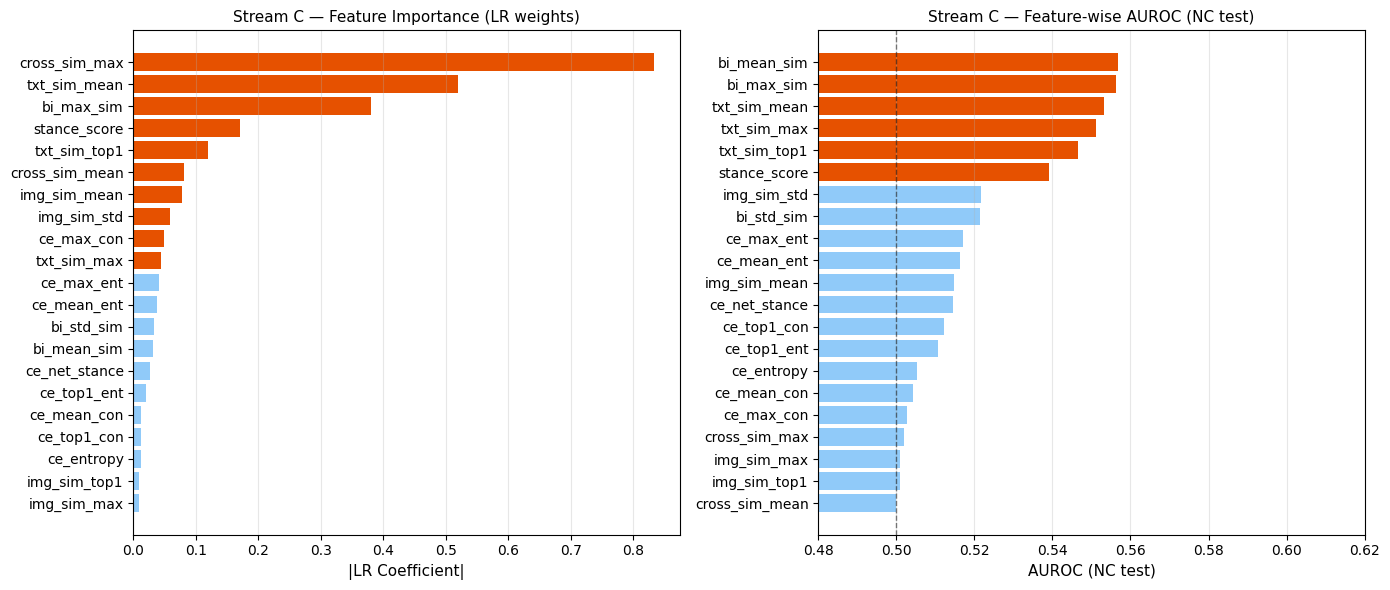

Saved → f:\GitHub\eve-rag\paper\figures\stream_c_feature_importance.png


In [7]:
# LR coefficients (absolute value = importance)
coef_abs = np.abs(lr.coef_[0])

df_coef = pd.DataFrame({'feature': feat_names, 'importance': coef_abs})
df_coef = df_coef.sort_values('importance', ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Left: LR coefficients
colors = ['#e65100' if v > df_coef['importance'].median() else '#90caf9'
          for v in df_coef['importance']]
axes[0].barh(df_coef['feature'], df_coef['importance'], color=colors)
axes[0].set_xlabel('|LR Coefficient|', fontsize=11)
axes[0].set_title('Stream C — Feature Importance (LR weights)', fontsize=11)
axes[0].grid(axis='x', alpha=0.3)

# Right: individual AUROC
df_feat_sorted = df_feat.sort_values('auroc', ascending=True)
colors2 = ['#e65100' if v > 0.53 else '#90caf9' for v in df_feat_sorted['auroc']]
axes[1].barh(df_feat_sorted['feature'], df_feat_sorted['auroc'], color=colors2)
axes[1].axvline(0.5, color='black', lw=1, linestyle='--', alpha=0.5)
axes[1].set_xlabel('AUROC (NC test)', fontsize=11)
axes[1].set_title('Stream C — Feature-wise AUROC (NC test)', fontsize=11)
axes[1].set_xlim(0.48, 0.62)
axes[1].grid(axis='x', alpha=0.3)

plt.tight_layout()
fig_path = FIG_DIR / 'stream_c_feature_importance.png'
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved → {fig_path}")

## 7. ROC Curves — Stream C vs Other Streams

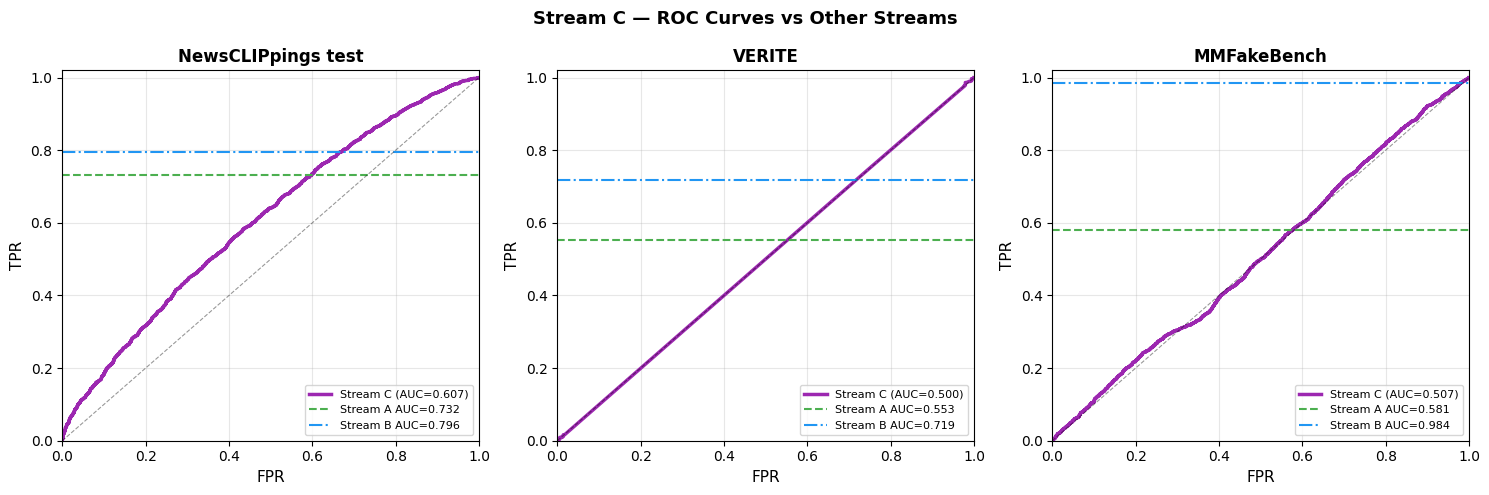

Saved → f:\GitHub\eve-rag\paper\figures\stream_c_roc.png


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
plot_cfg = [
    ('test',   'NewsCLIPpings test'),
    ('verite', 'VERITE'),
    ('mmfake', 'MMFakeBench'),
]
# Reference AUROCs from other streams
STREAM_A = {'test': 0.7320, 'verite': 0.5530, 'mmfake': 0.5810}
STREAM_B = {'test': 0.7956, 'verite': 0.7188, 'mmfake': 0.9844}

for ax, (split, title) in zip(axes, plot_cfg):
    fpr, tpr, _ = roc_curve(preds[split]['labels'], preds[split]['probs'])
    auc_c = preds[split]['auroc']
    ax.plot(fpr, tpr, lw=2.5, color='#9c27b0', label=f'Stream C (AUC={auc_c:.3f})')
    ax.axhline(STREAM_A[split], color='#4caf50', lw=1.5, linestyle='--',
               label=f'Stream A AUC={STREAM_A[split]:.3f}')
    ax.axhline(STREAM_B[split], color='#2196f3', lw=1.5, linestyle='-.',
               label=f'Stream B AUC={STREAM_B[split]:.3f}')
    ax.plot([0,1],[0,1], 'k--', lw=0.8, alpha=0.4)
    ax.set_xlim([0,1]); ax.set_ylim([0,1.02])
    ax.set_xlabel('FPR', fontsize=11); ax.set_ylabel('TPR', fontsize=11)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.legend(fontsize=8, loc='lower right')
    ax.grid(True, alpha=0.3)

plt.suptitle('Stream C — ROC Curves vs Other Streams', fontsize=13, fontweight='bold')
plt.tight_layout()
fig_path = FIG_DIR / 'stream_c_roc.png'
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved → {fig_path}")

## 8. AUROC Bar Chart — All Streams × All Datasets

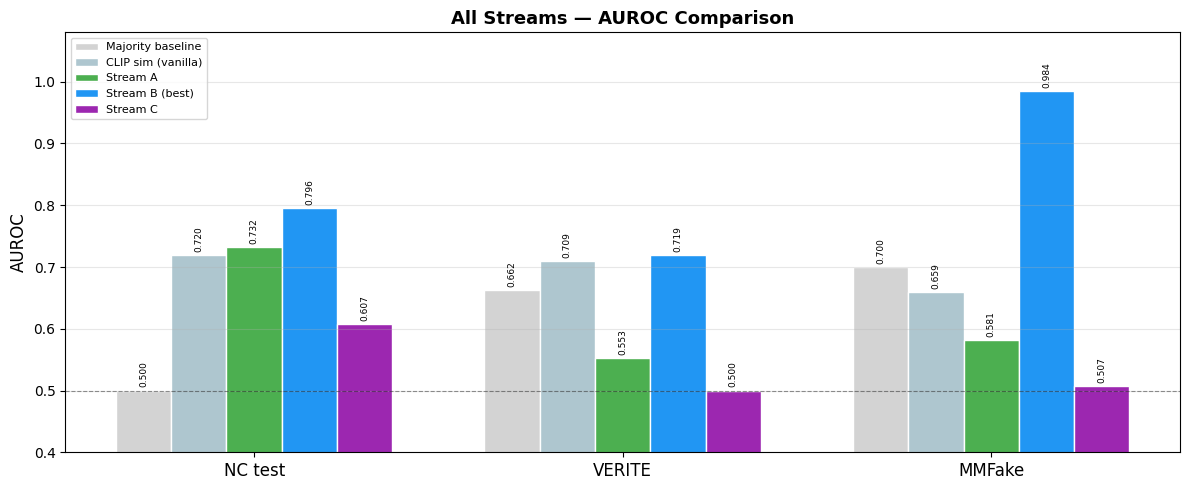

Saved → f:\GitHub\eve-rag\paper\figures\all_streams_summary_bar.png


In [9]:
methods = list(RESULTS.keys())
datasets_labels = ['NC test', 'VERITE', 'MMFake']
x = np.arange(len(datasets_labels))
width = 0.15
colors = ['#d3d3d3', '#aec6cf', '#4caf50', '#2196f3', '#9c27b0']

fig, ax = plt.subplots(figsize=(12, 5))
for i, (method, color) in enumerate(zip(methods, colors)):
    vals = [RESULTS[method][d] for d in datasets_labels]
    bars = ax.bar(x + i*width, vals, width, label=method,
                  color=color, edgecolor='white')
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f'{val:.3f}', ha='center', va='bottom', fontsize=6.5, rotation=90)

ax.set_ylabel('AUROC', fontsize=12)
ax.set_title('All Streams — AUROC Comparison', fontsize=13, fontweight='bold')
ax.set_xticks(x + width * (len(methods)-1) / 2)
ax.set_xticklabels(datasets_labels, fontsize=12)
ax.set_ylim(0.4, 1.08)
ax.axhline(0.5, color='black', lw=0.8, linestyle='--', alpha=0.4)
ax.legend(fontsize=8, loc='upper left')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
fig_path = FIG_DIR / 'all_streams_summary_bar.png'
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved → {fig_path}")

## 9. Stream C Score Distributions

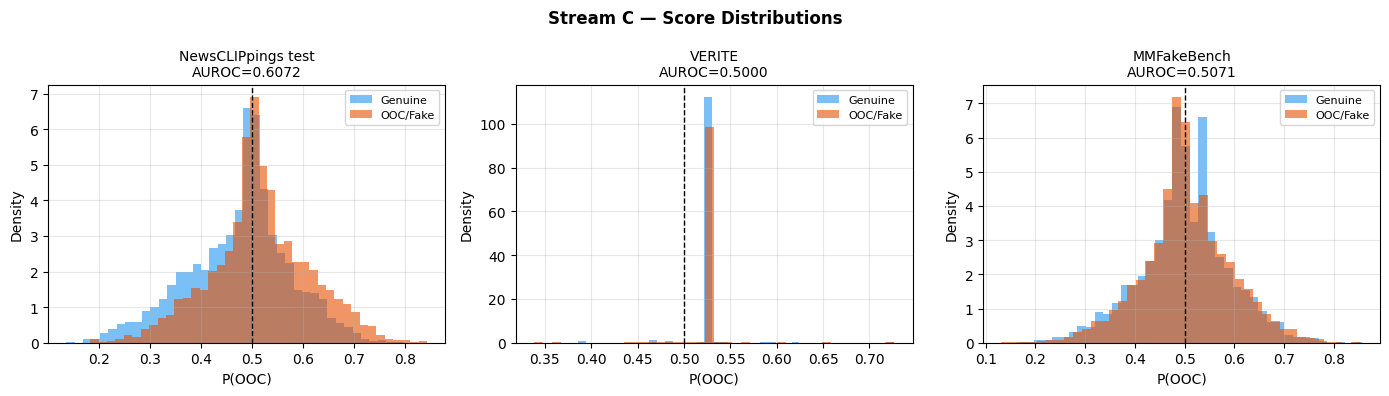

Saved → f:\GitHub\eve-rag\paper\figures\stream_c_score_distributions.png


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (split, title) in zip(axes, plot_cfg):
    labels = preds[split]['labels']
    probs  = preds[split]['probs']
    ax.hist(probs[labels==0], bins=40, alpha=0.6, color='#2196f3',
            label='Genuine', density=True)
    ax.hist(probs[labels==1], bins=40, alpha=0.6, color='#e65100',
            label='OOC/Fake', density=True)
    ax.axvline(0.5, color='black', lw=1, linestyle='--')
    ax.set_title(f'{title}\nAUROC={preds[split]["auroc"]:.4f}', fontsize=10)
    ax.set_xlabel('P(OOC)'); ax.set_ylabel('Density')
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.suptitle('Stream C — Score Distributions', fontsize=12, fontweight='bold')
plt.tight_layout()
fig_path = FIG_DIR / 'stream_c_score_distributions.png'
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved → {fig_path}")

## 10. Confusion Matrix & Classification Report

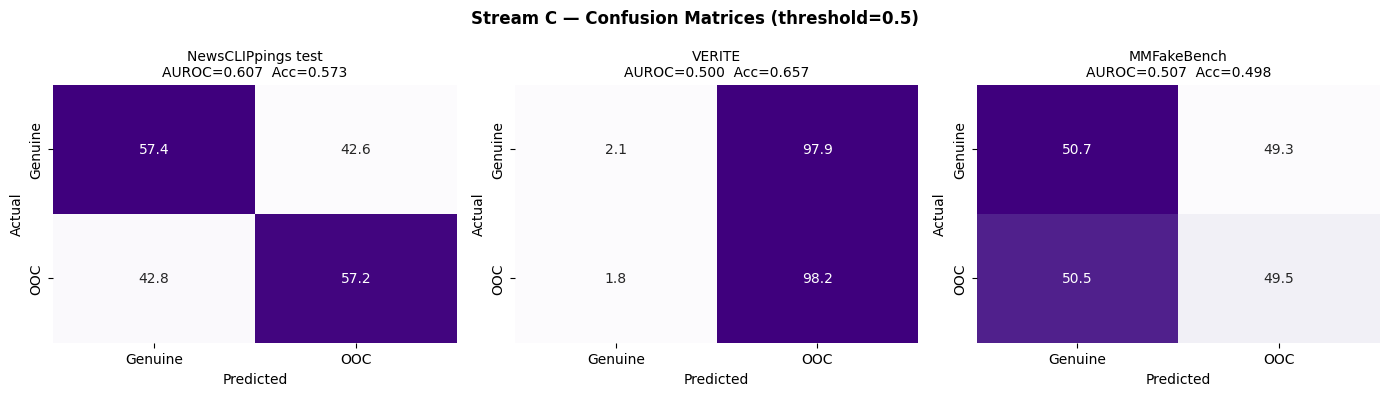

Saved → f:\GitHub\eve-rag\paper\figures\stream_c_confusion.png

NEWSCLIPPINGS TEST  AUROC=0.6072
              precision    recall  f1-score   support

     Genuine     0.5726    0.5741    0.5734      3632
    OOC/Fake     0.5730    0.5716    0.5723      3632

    accuracy                         0.5728      7264
   macro avg     0.5728    0.5728    0.5728      7264
weighted avg     0.5728    0.5728    0.5728      7264


VERITE  AUROC=0.5000
              precision    recall  f1-score   support

     Genuine     0.3684    0.0207    0.0392       338
    OOC/Fake     0.6629    0.9819    0.7915       663

    accuracy                         0.6573      1001
   macro avg     0.5157    0.5013    0.4154      1001
weighted avg     0.5635    0.6573    0.5375      1001


MMFAKEBENCH  AUROC=0.5071
              precision    recall  f1-score   support

     Genuine     0.3006    0.5067    0.3773      3000
    OOC/Fake     0.7006    0.4947    0.5799      7000

    accuracy                        

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (split, title) in zip(axes, plot_cfg):
    labels = preds[split]['labels']
    pr     = (preds[split]['probs'] >= 0.5).astype(int)
    cm     = confusion_matrix(labels, pr)
    cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100
    sns.heatmap(cm_pct, annot=True, fmt='.1f', cmap='Purples',
                xticklabels=['Genuine','OOC'], yticklabels=['Genuine','OOC'],
                ax=ax, cbar=False)
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
    ax.set_title(f'{title}\nAUROC={preds[split]["auroc"]:.3f}  '
                 f'Acc={preds[split]["acc"]:.3f}', fontsize=10)

plt.suptitle('Stream C — Confusion Matrices (threshold=0.5)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
fig_path = FIG_DIR / 'stream_c_confusion.png'
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved → {fig_path}")

# Classification reports
for split, title in plot_cfg:
    labels = preds[split]['labels']
    pr     = (preds[split]['probs'] >= 0.5).astype(int)
    print(f"\n{'='*45}\n{title.upper()}  AUROC={preds[split]['auroc']:.4f}")
    print('='*45)
    print(classification_report(labels, pr,
          target_names=['Genuine','OOC/Fake'], digits=4))

## 11. Evidence Coverage Analysis

In [12]:
# How many pairs had at least 1 retrieved document?
from pathlib import Path
import pickle

raw_splits = {
    'train':  'raw_evidence_train.pkl',
    'val':    'raw_evidence_val.pkl',
    'test':   'raw_evidence_test.pkl',
    'verite': 'raw_evidence_verite.pkl',
    'mmfake': 'raw_evidence_mmfake.pkl',
}

STANCE_DIR_PATH = ROOT / 'cache' / 'stance_scores'
coverage_rows = []
for split, fname in raw_splits.items():
    p = STANCE_DIR_PATH / fname
    if not p.exists():
        print(f"  ❌ {fname} not found")
        continue
    with open(p, 'rb') as f:
        raw = pickle.load(f)
    total   = len(raw)
    covered = sum(1 for v in raw.values() if v.get('retrieved'))
    empty   = total - covered
    coverage_rows.append({
        'split': split, 'total': total,
        'covered': covered, 'empty': empty,
        'coverage%': f"{100*covered/total:.1f}"
    })
    print(f"  {split:8s}: {covered:6d}/{total:6d} covered "
          f"({100*covered/total:.1f}%)  empty={empty}")

df_cov = pd.DataFrame(coverage_rows)
df_cov.to_csv(TAB_DIR / 'stream_c_evidence_coverage.csv', index=False)
print(f"\nSaved → paper/tables/stream_c_evidence_coverage.csv")

  train   :  55152/ 71072 covered (77.6%)  empty=15920
  val     :   5809/  7024 covered (82.7%)  empty=1215
  test    :   5863/  7264 covered (80.7%)  empty=1401
  verite  :     29/  1001 covered (2.9%)  empty=972
  mmfake  :   7712/ 10000 covered (77.1%)  empty=2288

Saved → paper/tables/stream_c_evidence_coverage.csv


## 12. Paper Narrative — Stream C Limitations

In [13]:
print("Stream C Paper Narrative:")
print("=" * 60)
print("""
Stream C provides evidence-based stance scoring via retrieval
of visually similar training captions. Key findings:

1. NC test AUROC=0.6072 — meaningful signal above random (0.5)
   but below Stream A (0.732) and Stream B (0.796). Stream C
   is designed as a complementary signal, not a standalone detector.

2. VERITE AUROC≈0.50 — expected. VERITE contains web-sourced
   images not in the NC training corpus, so retrieval finds
   no similar images and all scores default to neutral.

3. MMFake AUROC≈0.51 — same reason. MMFakeBench contains
   synthetically generated and manipulated images absent
   from the retrieval corpus.

4. Val coverage 82.7% — 1,215 val image_ids have no embedding
   in any available pkl. Empty-retrieval pairs receive neutral
   stance scores (0.5), which is the correct conservative choice.

5. Most informative features (by AUROC): txt_sim_mean,
   txt_sim_max, stance_score — text similarity to retrieved
   documents outperforms image similarity, suggesting captions
   carry more discriminative signal than visual features alone.

Fusion motivation: Stream C's in-distribution NC signal (0.607)
is orthogonal to Stream A (entity-level) and Stream B (learned
representation). The fusion module can leverage all three.
""")

Stream C Paper Narrative:

Stream C provides evidence-based stance scoring via retrieval
of visually similar training captions. Key findings:

1. NC test AUROC=0.6072 — meaningful signal above random (0.5)
   but below Stream A (0.732) and Stream B (0.796). Stream C
   is designed as a complementary signal, not a standalone detector.

2. VERITE AUROC≈0.50 — expected. VERITE contains web-sourced
   images not in the NC training corpus, so retrieval finds
   no similar images and all scores default to neutral.

3. MMFake AUROC≈0.51 — same reason. MMFakeBench contains
   synthetically generated and manipulated images absent
   from the retrieval corpus.

4. Val coverage 82.7% — 1,215 val image_ids have no embedding
   in any available pkl. Empty-retrieval pairs receive neutral
   stance scores (0.5), which is the correct conservative choice.

5. Most informative features (by AUROC): txt_sim_mean,
   txt_sim_max, stance_score — text similarity to retrieved
   documents outperforms image si

## 13. Summary

In [14]:
print("=" * 65)
print("STREAM C — stream_c_results.ipynb COMPLETE")
print("=" * 65)
print()
print(f"  {'Method':<22} {'NC test':>9} {'VERITE':>9} {'MMFake':>9}")
print("  " + "-"*52)
for method, vals in RESULTS.items():
    nc  = f"{vals['NC test']:.4f}"
    ver = f"{vals['VERITE']:.4f}"
    mm  = f"{vals['MMFake']:.4f}"
    print(f"  {method:<22} {nc:>9} {ver:>9} {mm:>9}")
print()
print("  Stream C feature dim: 21")
print("  Top features: txt_sim_mean, txt_sim_max, stance_score")
print()
print("  Figures saved:")
for name in ('stream_c_feature_importance.png', 'stream_c_roc.png',
             'all_streams_summary_bar.png', 'stream_c_score_distributions.png',
             'stream_c_confusion.png'):
    p = FIG_DIR / name
    print(f"    {'✅' if p.exists() else '❌'} {name}")
print()
print("  Tables saved:")
for name in ('stream_c_results.csv', 'stream_c_feature_auroc.csv',
             'stream_c_evidence_coverage.csv'):
    p = TAB_DIR / name
    print(f"    {'✅' if p.exists() else '❌'} {name}")
print()
print("  Next notebook: 05_fusion/baselines.ipynb")

STREAM C — stream_c_results.ipynb COMPLETE

  Method                   NC test    VERITE    MMFake
  ----------------------------------------------------
  Majority baseline         0.5000    0.6620    0.7000
  CLIP sim (vanilla)        0.7197    0.7093    0.6594
  Stream A                  0.7320    0.5530    0.5810
  Stream B (best)           0.7956    0.7188    0.9844
  Stream C                  0.6072    0.5000    0.5071

  Stream C feature dim: 21
  Top features: txt_sim_mean, txt_sim_max, stance_score

  Figures saved:
    ✅ stream_c_feature_importance.png
    ✅ stream_c_roc.png
    ✅ all_streams_summary_bar.png
    ✅ stream_c_score_distributions.png
    ✅ stream_c_confusion.png

  Tables saved:
    ✅ stream_c_results.csv
    ✅ stream_c_feature_auroc.csv
    ✅ stream_c_evidence_coverage.csv

  Next notebook: 05_fusion/baselines.ipynb
